#**Visão Computacional**
O processamento de imagens digitais é uma área fundamental dentro da Visão Computacional e envolve a aplicação de operações matemáticas e computacionais sobre imagens digitais com o objetivo de melhorar sua qualidade, realçar detalhes específicos ou extrair características que possam ser utilizadas em diferentes aplicações.

Enquanto os seres humanos interpretam imagens de forma intuitiva — reconhecendo formas, cores, padrões e objetos — os computadores veem imagens apenas como matrizes de números, onde cada valor corresponde à intensidade de luz (em tons de cinza) ou às intensidades dos canais de cor, como vermelho, verde e azul. O processamento de imagens atua, portanto, como uma ponte entre essa representação numérica e a interpretação que desejamos dar às imagens.

# Fundamentos

###**Objetivos da atividade**:
- analisar criticamente os efeitos de cada técnica;
- compreender como os filtros modificam a percepção da imagem;
- de que forma a segmentação ajuda a destacar regiões de interesse;
- como a extração de características torna possível identificar e comparar padrões visuais em diferentes contextos.

In [ ]:
pip install opencv-python numpy matplotlib

In [ ]:
import cv2 # principal biblioteca para processamento de imagens e visão computacional
import numpy as np # usada para manipular matrizes e arrays (base da representação digital das imagens)
import matplotlib.pyplot as plt # usada para exibir gráficos e imagens

In [ ]:
def show_images(images, titles=None, cmap=None, figsize=(15, 5)): # define o tamanho da janela para exibição
  """função auxiliar para exibir um lista de imagens lado a lado com títulos"""
  plt.figure(figsize=figsize)
  for i, (img, title) in enumerate(zip(images, titles)): # percorre cada imagem junto com seu respectivo título
    plt.subplot(1, len(images), i + 1)
    if len(img.shape) == 2: # detecta se a imagem é em escala de cinza
      plt.imshow(img, cmap=cmap if cmap else 'gray')
    else:
      plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)) # converte a ordem de cores do OpenCV (BRG) para a ordem usada no Matplotlib (RGB)
    plt.title(title)
    plt.axis("off")
  plt.show()

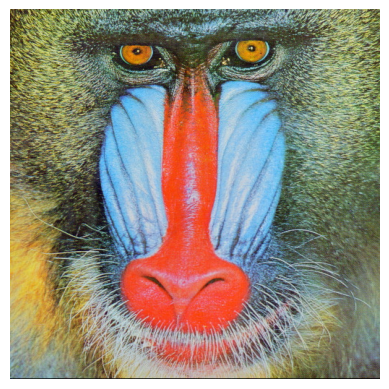

In [ ]:
import urllib.request

url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg?"

resp = urllib.request.urlopen(url) # abre a URL fornecida e obtém o conteúdo da imagem como um fluxo de bytes

image = np.asarray(bytearray(resp.read()), dtype="uint8")
# lê todo o conteúdo da resposta (os bytes da imagem) da URL
# converte os bytes da imagem em um array NumPy de inteiros de 8 bits, que é o formato esperado pelo OpenCV para decodificação de imagens

img = cv2.imdecode(image, cv2.IMREAD_COLOR)
# decodifica o array NumPy em uma imagem colorida (BGR) que pode ser manipulada pelo OpenCV


# exibindo para testar
from matplotlib import pyplot as plt

# exibe a imagem no Matplotlib
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
# converte a imagem do formato BGR do OpenCV para RGB, que é o formato correto para exibição com o Matplotlib

plt.axis("off")
# remove os eixos da figura para uma visualização limpa

plt.show()
# renderiza a imagem na janela de saída do Matplotlib

1.   **Filtros** – São operações aplicadas diretamente nos pixels da imagem, com a finalidade de suavizar ruídos, destacar bordas ou realçar detalhes importantes. Por exemplo, um filtro de média pode ser usado para suavizar uma foto ruidosa, enquanto o filtro de Canny é eficaz para destacar contornos.

* Filtro de Média (Blur) – suavização simples por média da vizinhança.
* Filtro Gaussiano – suavização com pesos, preservando mais detalhes.
* Filtro Sobel – realce de bordas a partir de derivadas.
* Detector de Bordas Canny – método robusto para contornos.

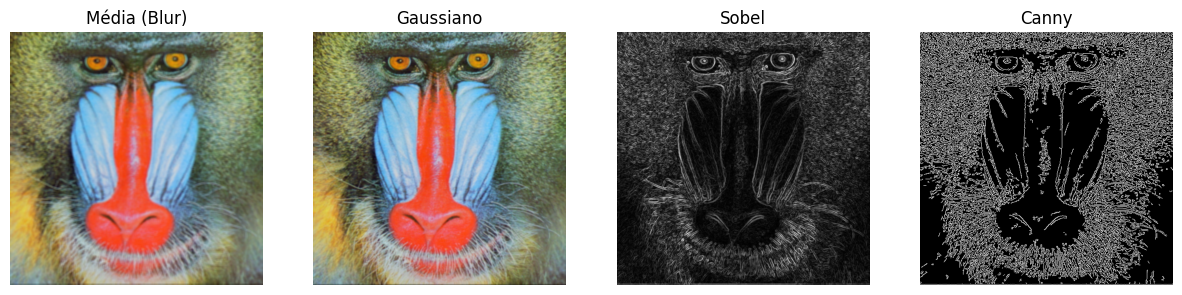

In [ ]:
# Filtros de suavização e detecção de bordas

# 1. Filtro de Média (Blur)
# Substitui cada pixel pela média da vizinhança (5x5 neste caso).
blur = cv2.blur(img, (5,5))

# 2. Filtro Gaussiano
# Similar ao blur, mas aplica pesos conforme a distribuição gaussiana,
# preservando melhor as bordas e estruturas.
gaussian = cv2.GaussianBlur(img, (5,5), 0)

# 3. Conversão para escala de cinza
# Necessária para aplicar filtros baseados em intensidade (ex.: Sobel e Canny).
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 4. Filtro Sobel
# Calcula derivadas nas direções x e y, destacando transições de intensidade.
sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5)
sobel = cv2.magnitude(sobelx, sobely)

# 5. Detector de Bordas Canny
# Método mais robusto, que destaca bordas fortes e contínuas.
canny = cv2.Canny(gray, 100, 200)

show_images([blur, gaussian, sobel, canny],
            ["Média (Blur)", "Gaussiano", "Sobel", "Canny"])

###**Análise dos Resultados**  
**Filtro de Média (Blur)**: A imagem fica mais borrada, o ruído é suavizado, mas a nitidez dos detalhes é perdida.  
**Filtro Gaussiano**: Também suaviza, mas preserva melhor as estruturas importantes da imagem, sendo mais eficaz que o blur simples.  
**Filtro Sobel**: Destaca bordas e transições de intensidade, revelando contornos principais da imagem.  
**Detector de Bordas Canny**: É mais refinado e seletivo, capturando apenas as bordas mais fortes e contínuas, muito usado em visão computacional.

2.   **Segmentação** – Trata-se do processo de dividir a imagem em regiões significativas. Pode ser feito de forma simples, com um threshold que separa fundo e objeto, ou de forma mais sofisticada, como com o uso de algoritmos de clustering (exemplo: K-means), que agrupam pixels de cores semelhantes. A segmentação é fundamental para sistemas que precisam localizar e isolar objetos em uma cena.

* Thresholding: separa pixels de acordo com um valor de intensidade. É útil em casos em que há contraste claro entre fundo e objeto (por exemplo, um texto preto sobre fundo branco). A versão adaptativa melhora essa ideia ajustando o limiar para cada região, o que é vantajoso em situações de iluminação irregular.  
* Segmentação baseada em agrupamento (clustering), como o K-means, agrupa pixels com características semelhantes (cor ou intensidade). Isso é útil em imagens coloridas, onde queremos separar objetos por tonalidade, como distinguir céu, vegetação e solo em uma paisagem

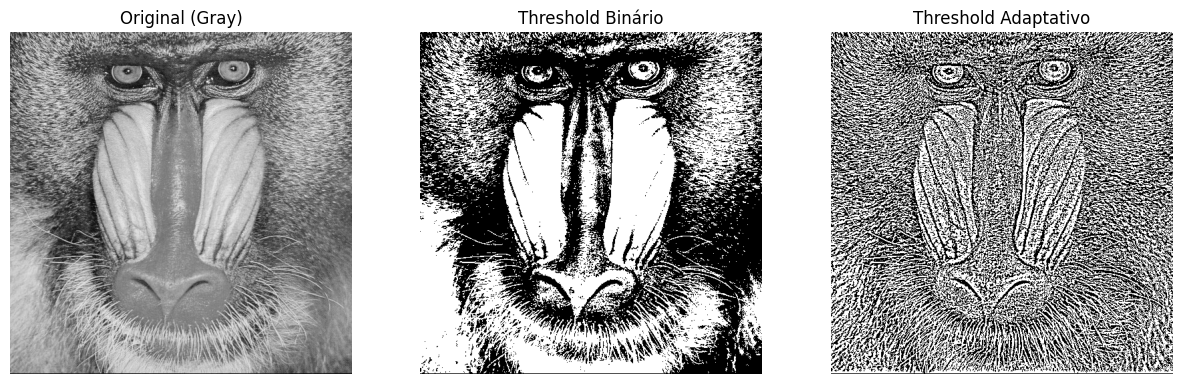

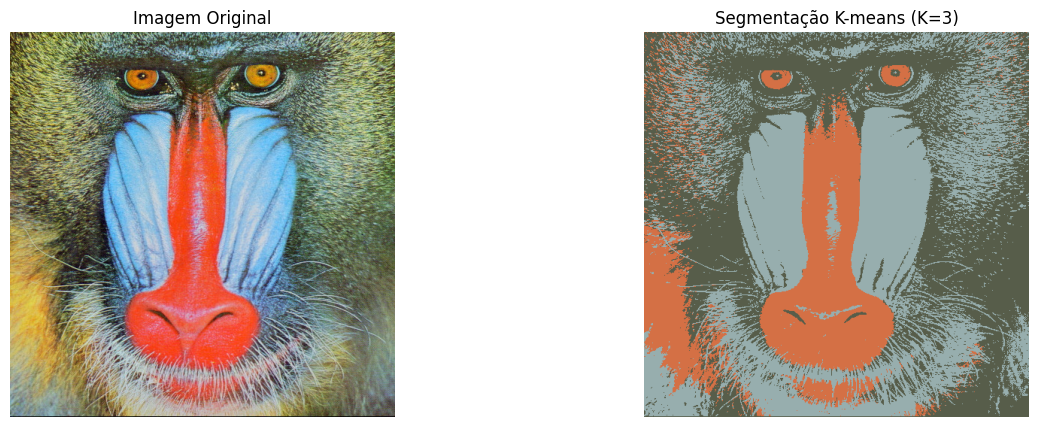

In [23]:
# Segmentação de Imagens

# 1.1. Thresholding Simples
# Define um valor fixo de limiar (127). Pixels acima dele viram branco, abaixo viram preto.
ret, thresh_bin = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 1.2. Thresholding Adaptativo
# Calcula limiares localmente em diferentes regiões da imagem,
# útil quando a iluminação não é uniforme.
thresh_adapt = cv2.adaptiveThreshold(
    gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,  # usa média ponderada gaussiana
    cv2.THRESH_BINARY,
    11, 2
)

show_images(
    [gray, thresh_bin, thresh_adapt],
    ["Original (Gray)", "Threshold Binário", "Threshold Adaptativo"]
)

# 2. Segmentação por K-means
# Reorganiza a imagem em clusters de cores semelhantes.

# Pré-processamento: transforma a imagem em um array 2D de pixels
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# Critério de parada do algoritmo e número de clusters (K)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 3  # número de grupos de cor
_, labels, centers = cv2.kmeans(Z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Reconstruindo a imagem segmentada
centers = np.uint8(centers)
segmented = centers[labels.flatten()].reshape(img.shape)

# Exibindo original e segmentada
show_images(
    [img, segmented],
    ["Imagem Original", "Segmentação K-means (K=3)"]
)

###**Análise dos Resultados**
**Threshold Binário**: funciona bem em imagens com alto contraste, mas falha quando a iluminação varia.  
**Threshold Adaptativo**: adapta o limiar localmente, sendo mais robusto em cenários com sombras ou iluminação irregular.  
**K-means**: agrupa pixels por cor/intensidade, separando regiões de tonalidades semelhantes. É útil quando se deseja destacar objetos com cores específicas.

3.   **Extração de características (features)** – Envolve a identificação de pontos de interesse, como cantos, bordas marcantes ou padrões locais, que funcionam como “assinaturas” únicas da imagem. Esses pontos são amplamente usados em tarefas de reconhecimento, correspondência entre imagens diferentes e rastreamento de objetos em movimento. Técnicas como Shi-Tomasi e ORB são exemplos que exploraremos.

* Detecção de cantos (Shi-Tomasi ou Harris): cantos são locais da imagem onde há mudança brusca em duas direções (como o cruzamento de bordas). São pontos estáveis e fáceis de identificar.  
* Descritores locais (ORB, SIFT, SURF): além de detectar os pontos de interesse, eles criam um vetor numérico que descreve a região em torno de cada ponto. Esses descritores permitem que os pontos sejam comparados entre imagens diferentes.

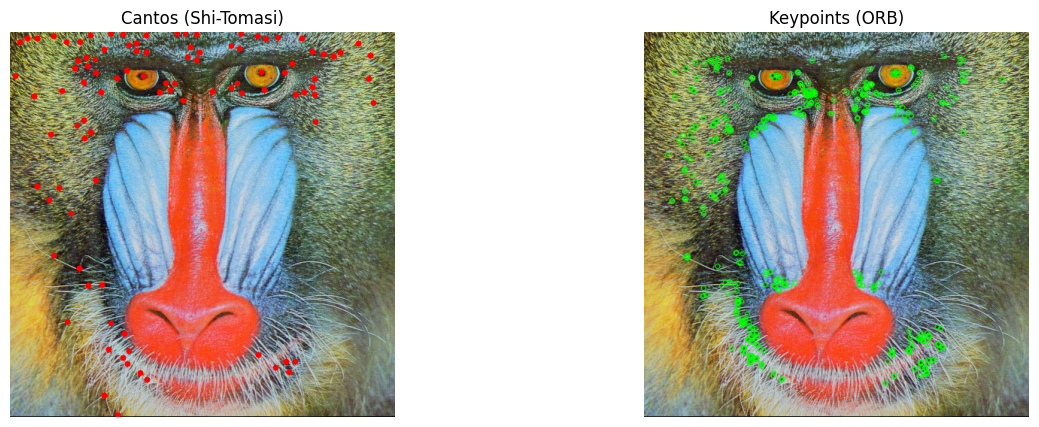

In [24]:
# 4. Extração de Features

# 1. Detecção de Cantos (Shi-Tomasi)
# Detecta pontos onde a variação de intensidade é alta em duas direções.
corners = cv2.goodFeaturesToTrack(gray,
                                  maxCorners=100,     # número máximo de cantos
                                  qualityLevel=0.01,  # qualidade mínima do ponto
                                  minDistance=10)     # distância mínima entre cantos
corners = np.intp(corners)

# Criamos uma cópia da imagem para desenhar os cantos detectados
img_corners = img.copy()
for c in corners:
    x, y = c.ravel()
    cv2.circle(img_corners, (x, y), 4, (0, 0, 255), -1)  # círculo vermelho

# 2. ORB (Oriented FAST and Rotated BRIEF)
# Detecta pontos-chave e cria descritores para comparação entre imagens.
orb = cv2.ORB_create()
kp, des = orb.detectAndCompute(gray, None)

# Desenhando os keypoints encontrados na imagem
img_orb = cv2.drawKeypoints(img, kp, None,
                            color=(0, 255, 0),   # verde
                            flags=0)

show_images([img_corners, img_orb],
            ["Cantos (Shi-Tomasi)", "Keypoints (ORB)"])

###**Análise dos Resultados**

**Shi-Tomasi**: Detecta cantos da imagem, que são regiões onde a variação de intensidade ocorre em duas direções diferentes. Esses pontos são úteis para rastreamento de movimento em vídeos ou para localizar pontos de interesse estáveis.  
**ORB**: Além de localizar pontos-chave, gera descritores numéricos que podem ser usados para comparar imagens. Isso permite, por exemplo, reconhecer o mesmo objeto em diferentes fotos, mesmo que ele esteja em outra posição, com outra escala ou rotacionado.